# Clase 5 — Actividad integradora

## Del servicio web al gráfico

El objetivo es construir un pequeño informe meteorológico utilizando módulos, una API, pandas y Matplotlib.

El recorrido será:

```text
API → JSON → lista de diccionarios → DataFrame → análisis → gráfico
```

## Consigna

Desarrollá un informe sobre el clima de una ciudad elegida.

Podés utilizar Open-Meteo o trabajar con el CSV local si no hay conexión. El programa debe:

1. Consultar al menos tres variables diarias.
2. Controlar los posibles errores de conexión.
3. Convertir los datos en un DataFrame.
4. Calcular al menos tres indicadores.
5. Filtrar los datos con una condición.
6. Crear dos gráficos diferentes.
7. Guardar al menos un gráfico como PNG.
8. Registrar los prompts utilizados con Copilot.

## 1. Configuración

Completá los datos de la ciudad. Las coordenadas deben escribirse como números.

In [10]:
# Definimos los datos básicos de la ciudad que vamos a analizar. #, 
CIUDAD: str = "San Pedro"
LATITUD: float = -33.6783
LONGITUD: float = -59.6671
FECHA_INICIO: str = "2026-10-01"
FECHA_FIN: str = "2026-10-15"

# La URL apunta al servicio de Open-Meteo que devuelve datos históricos del clima.
URL: str = "https://archive-api.open-meteo.com/v1/archive"

## 2. Consulta a la API

Escribí una función `consultar_clima()` que reciba ubicación y fechas. Debe devolver un diccionario o `None` si falla.

In [11]:
# Importamos requests para consultar una API meteorológica desde Python.
import requests

def consultar_clima(
    latitud: float,
    longitud: float,
    fecha_inicio: str,
    fecha_fin: str,
) -> dict | None:

    # Parámetros de la consulta
    parametros = {
        "latitude": latitud,
        "longitude": longitud,
        "start_date": fecha_inicio,
        "end_date": fecha_fin,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_sum"
        ],
        "timezone": "America/Argentina/Buenos_Aires"
    }

    try:
        # Realizamos la petición HTTP
        respuesta = requests.get(
            URL,
            params=parametros,
            timeout=60
        )

        # Verificamos si hubo errores HTTP
        respuesta.raise_for_status()

        # Convertimos el JSON en un diccionario
        datos_api = respuesta.json()

        print("Consulta realizada correctamente.")
        print("Código HTTP:", respuesta.status_code)

        return datos_api

    except (requests.RequestException, ValueError) as error:
        print("No fue posible consultar la API.")
        print("Detalle:", error)

        return None



Consulta realizada correctamente.
Código HTTP: 200


### Registro del prompt

**Prompt utilizado:**  
Escribir aquí.

**¿Qué cambiaste o corregiste de la propuesta?**  
Escribir aquí.

## 3. Crear el DataFrame

Transformá la respuesta de la API en una tabla. Si la consulta falla, cargá `datos/clima_buenos_aires.csv`.

In [12]:
# Importamos Path para manejar rutas y pandas para convertir los datos en un DataFrame.
from pathlib import Path

import pandas as pd

# Aquí se debe consultar la API o cargar el CSV local y convertir la respuesta en una tabla.

# Si la consulta falla, se puede usar los datos del archivo clima_buenos_aires.csv.clima: pd.DataFrame | None = None

datos_api: dict | None = consultar_clima(
    latitud=LATITUD,
    longitud=LONGITUD,
    fecha_inicio=FECHA_INICIO,
    fecha_fin=FECHA_FIN
)

if datos_api is not None:
    # Convertimos los datos de la API en un DataFrame
    clima: pd.DataFrame = pd.DataFrame(datos_api["daily"])
else:
    # Cargamos los datos desde un archivo CSV local
    ruta_csv: Path = Path("clima_buenos_aires.csv")
    clima: pd.DataFrame = pd.read_csv(ruta_csv)


Consulta realizada correctamente.
Código HTTP: 200


## 4. Analizar los datos

Calculá al menos tres indicadores. Por ejemplo:

- temperatura máxima promedio;
- temperatura mínima promedio;
- precipitación acumulada;
- día más cálido;
- día más lluvioso;
- amplitud térmica promedio.

In [14]:
# En esta celda se calculan indicadores del clima, por ejemplo promedio, suma, máximos o días más lluviosos.
# Escribí aquí los cálculos.
def calcular_promedio_minimas(df: pd.DataFrame) -> float:
    return df["temperature_2m_min"].mean()  

def calcular_promedio_maximas(df: pd.DataFrame) -> float:
    return df["temperature_2m_max"].mean()

#Precipitacion acumulada
def calcular_precipitacion_acumulada(df: pd.DataFrame) -> float:
    return df["precipitation_sum"].sum()   

def dia_mas_caluroso(df: pd.DataFrame) -> pd.Series:
    return df.loc[df["temperature_2m_max"].idxmax()]

def dia_mas_lluvioso(df: pd.DataFrame) -> pd.Series:
    return df.loc[df["precipitation_sum"].idxmax()]

def amplitud_termica_promedio(df: pd.DataFrame) -> float:
    return (df["temperature_2m_max"] - df["temperature_2m_min"]).mean()

print(f"Promedio de mínimas: {calcular_promedio_minimas(clima):.2f} °C")
print(f"Promedio de máximas: {calcular_promedio_maximas(clima):.2f} °C")
print(f"Precipitación acumulada: {calcular_precipitacion_acumulada(clima):.2f} mm")
print(f"Día más caluroso: {dia_mas_caluroso(clima)['time']} con {dia_mas_caluroso(clima)['temperature_2m_max']:.2f} °C")
print   (f"Día más lluvioso: {dia_mas_lluvioso(clima)['time']} con {dia_mas_lluvioso(clima)['precipitation_sum']:.2f} mm")
print(f"Amplitud térmica promedio: {amplitud_termica_promedio(clima):.2f} °C")  




Promedio de mínimas: 11.25 °C
Promedio de máximas: 19.37 °C
Precipitación acumulada: 35.90 mm
Día más caluroso: 2026-10-04 con 23.30 °C
Día más lluvioso: 2026-10-07 con 16.20 mm
Amplitud térmica promedio: 8.13 °C


## 5. Crear los gráficos

Generá dos visualizaciones diferentes y guardá una como PNG. Cada gráfico debe tener título, ejes identificados y una representación adecuada para los datos.

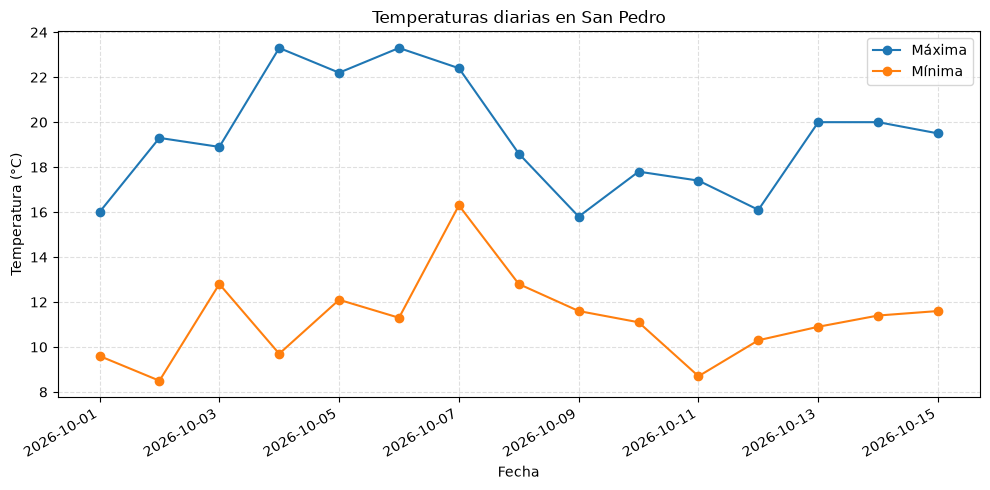

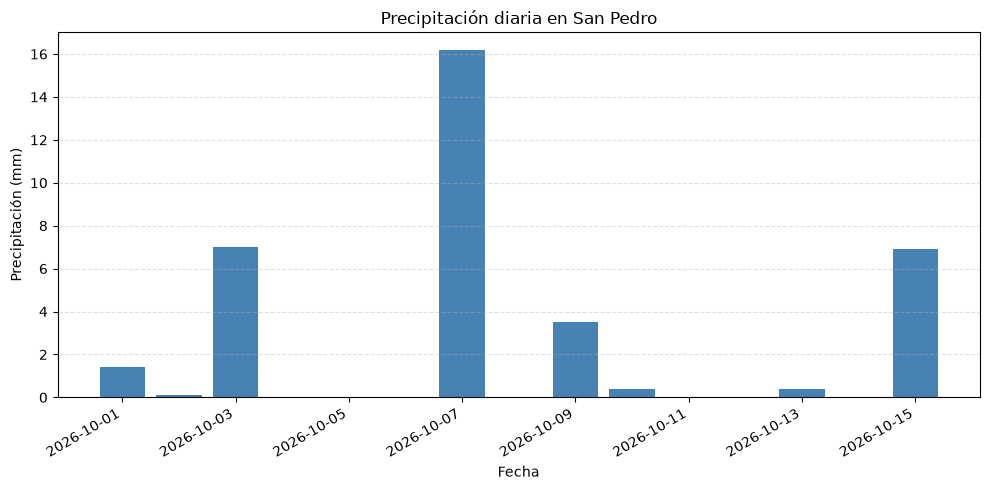

Gráficos guardados en: C:\Users\Admin\Desktop\Prog_Avanzada_IA\CLASE5\salidas


In [16]:
# Importamos matplotlib para generar gráficos a partir del DataFrame.
import matplotlib.pyplot as plt

# Creamos la carpeta de salida si todavía no existe.
ruta_salida = Path("salidas")
ruta_salida.mkdir(parents=True, exist_ok=True)

# Convertimos las fechas para que Matplotlib pueda representarlas correctamente.
fechas = pd.to_datetime(clima["time"])

# Gráfico 1: temperaturas máximas y mínimas por día.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fechas, clima["temperature_2m_max"], marker="o", label="Máxima")
ax.plot(fechas, clima["temperature_2m_min"], marker="o", label="Mínima")
ax.set_title(f"Temperaturas diarias en {CIUDAD}")
ax.set_xlabel("Fecha")
ax.set_ylabel("Temperatura (°C)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(ruta_salida / "temperaturas_diarias.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 2: precipitación acumulada por día.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(fechas, clima["precipitation_sum"], color="steelblue", width=0.8)
ax.set_title(f"Precipitación diaria en {CIUDAD}")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precipitación (mm)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(ruta_salida / "precipitacion_diaria.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Gráficos guardados en: {ruta_salida.resolve()}")

## 6. Comprobaciones

Agregá al menos cuatro pruebas con `assert`. Deben verificar resultados concretos, no solamente que el programa se ejecuta.

In [18]:
# En esta celda se agregan validaciones con assert para comprobar resultados concretos.
# Verificamos que el DataFrame tenga datos y las columnas necesarias.
assert not clima.empty, "El DataFrame no debe estar vacío."
assert {"time", "temperature_2m_max", "temperature_2m_min", "precipitation_sum"}.issubset(clima.columns), (
    "Faltan una o más columnas meteorológicas esperadas."
)

# Comprobamos que las temperaturas máximas sean mayores o iguales a las mínimas.
assert (clima["temperature_2m_max"] >= clima["temperature_2m_min"]).all(), (
    "Hay días cuya temperatura máxima es menor que la mínima."
)

# Comprobamos que la precipitación no tenga valores negativos.
assert (clima["precipitation_sum"] >= 0).all(), (
    "La precipitación no puede ser negativa."
)

# Verificamos también valores calculados concretos y consistentes con los datos.
assert calcular_precipitacion_acumulada(clima) >= 0, (
    "La precipitación acumulada no puede ser negativa."
)
assert calcular_promedio_maximas(clima) >= calcular_promedio_minimas(clima), (
    "El promedio de máximas debe ser mayor o igual al promedio de mínimas."
)

print("Todas las comprobaciones se realizaron correctamente.")

Todas las comprobaciones se realizaron correctamente.


## 7. Reflexión final

Respondé:

1. ¿Qué información llegó desde la API?
2. ¿Qué transformación realizó pandas?
3. ¿Qué aporta el gráfico que no resulta tan visible en la tabla?
4. ¿Qué parte resolvió Copilot y qué parte decidiste vos?
5. ¿Qué ocurriría si la API cambia el nombre de una clave?

**Respuesta:**  
Escribir aquí.

## Entrega

Entregar:

- notebook completa y ejecutada;
- gráfico PNG generado;
- prompts utilizados;
- reflexión final;
- cualquier archivo `.py` adicional que se haya creado.

Nombre del archivo:

```text
Apellido_Nombre_Clase5.ipynb
```